<a href="https://colab.research.google.com/github/Deangr-econ/Stock_volatility/blob/main/Stock_Vol.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [5]:
data_stocks = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/realized_variance_stocks_20261030.csv")

In [6]:
data_stocks.columns

Index(['date', 'symbol', 'asset_type', 'volume', 'trades', 'open_price',
       'close_price', 'high_price', 'low_price', 'pr', 'gkr', 'rr5', 'rv1',
       'rv5', 'rv5_ss', 'bv1', 'bv5', 'bv5_ss', 'rsp1', 'rsn1', 'rsp5', 'rsn5',
       'rsp5_ss', 'rsn5_ss', 'medrv1', 'medrv5', 'medrv5_ss', 'minrv1',
       'minrv5', 'minrv5_ss', 'rk', 'rq1', 'rq5', 'rq5_ss', 'index'],
      dtype='object')

In [7]:
# Pivot the dataframe to get date as index and semivariances as columns for each stock symbol
df = (data_stocks.pivot(index='date', columns='symbol', values='rv5_ss'))

def check_nans(matrix):
    """
    Checks if there are any NaN values in the DataFrame/matrix,
    returning the count and locations if any are found.
    """
    nan_count = matrix.isna().sum().sum()
    print(f"Total NaN values in matrix: {nan_count}")
    if nan_count > 0:
        print("Columns with NaNs and their counts:")
        print(matrix.isna().sum()[matrix.isna().sum() > 0])
    return nan_count > 0

check_nans(df)

Total NaN values in matrix: 0


np.False_

In [12]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

class FactorModelEvaluator:
    """
    An OOP-style Evaluator to run out-of-sample factor forecasting evaluations
    using either expanding or rolling window approaches, decoupling calculation of error matrices
    from their subsequent metrics evaluation and plotting.
    """
    def __init__(self, df, r_max=40, n_eval=800, window_size=1000):
        self.df = df
        self.r_max = r_max
        self.n_eval = n_eval
        self.window_size = window_size
        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        self.eval_dates = df.index[-n_eval:]

    def compute_expanding_errors(self):
        """
        Runs expanding window SVD and regression, returning a dictionary of
        error DataFrames (Actual - Forecast) indexed by evaluation dates for each r.
        """
        print(f"Computing expanding window errors on: {self.device}")
        log_df = np.log(self.df)
        X_raw = torch.tensor(log_df.values, dtype=torch.float32, device=self.device)
        T, N = X_raw.shape
        start_idx = T - self.n_eval

        errors_accumulator = {r: [] for r in range(1, self.r_max + 1)}

        for t in range(start_idx, T):
            X_win = X_raw[:t]
            mean_t = X_win.mean(dim=0, keepdim=True)
            std_t = X_win.std(dim=0, keepdim=True)
            X_norm = (X_win - mean_t) / std_t
            x_actual_norm = (X_raw[t : t + 1] - mean_t) / std_t

            # SVD
            U, S, _ = torch.linalg.svd(X_norm, full_matrices=False)
            F_full = U[:, :self.r_max] * S[:self.r_max].unsqueeze(0)

            F_train = F_full[:-1, :]
            Y_train = X_norm[1:, :]
            f_latest = F_full[-1:, :]

            # OLS prep
            FtF = F_train.T @ F_train
            FtY = F_train.T @ Y_train

            for r in range(1, self.r_max + 1):
                A = FtF[:r, :r]
                Beta_r = torch.linalg.solve(A, FtY[:r, :])
                x_pred = f_latest[:, :r] @ Beta_r
                err = (x_actual_norm - x_pred).cpu().numpy()[0]
                errors_accumulator[r].append(err)

        errors_by_r = {
            r: pd.DataFrame(errors_accumulator[r], index=self.eval_dates, columns=self.df.columns)
            for r in range(1, self.r_max + 1)
        }
        return errors_by_r

    def compute_rolling_errors(self):
        """
        Runs rolling window SVD and regression, returning a dictionary of
        error DataFrames (Actual - Forecast) indexed by evaluation dates for each r.
        """
        print(f"Computing rolling window errors on: {self.device}")
        df_aligned = self.df.iloc[-(self.window_size + self.n_eval) :]
        log_df = np.log(df_aligned)
        norm_df = (log_df - log_df.mean()) / log_df.std()
        X_val = norm_df.values

        X_tensor = torch.tensor(X_val, dtype=torch.float32, device=self.device)
        X_batched = X_tensor.unfold(0, self.window_size, 1).permute(0, 2, 1)[:-1].contiguous()
        B, W, N = X_batched.shape

        U_batched, S_batched, _ = torch.linalg.svd(X_batched, full_matrices=False)
        Y_train = X_batched[:, 1:, :]
        X_actual = X_tensor[self.window_size:, :].unsqueeze(1)

        errors_by_r = {}
        for r in range(1, self.r_max + 1):
            F_batched = U_batched[:, :, :r] * S_batched[:, :r].unsqueeze(1)
            F_train = F_batched[:, :-1, :]
            F_latest = F_batched[:, -1:, :]

            Ft = F_train.transpose(1, 2)
            FtF = torch.bmm(Ft, F_train)
            FtY = torch.bmm(Ft, Y_train)

            # Directly invert or solve since the batches are clean
            Beta = torch.bmm(torch.linalg.inv(FtF), FtY)
            X_pred = torch.bmm(F_latest, Beta)

            err_tensor = (X_actual - X_pred).squeeze(1).cpu().numpy()
            errors_by_r[r] = pd.DataFrame(err_tensor, index=self.eval_dates, columns=self.df.columns)

        return errors_by_r

    @staticmethod
    def evaluate_performance(errors_by_r, start_idx=0, end_idx=None):
        """
        Computes out-of-sample performance (RMSE and MAE) across a specific sub-window
        of the predictions (e.g. first 600 days for validation, or last 200 days for test).
        """
        metrics = []
        for r, err_df in errors_by_r.items():
            # Slice the errors to the desired sub-window
            err_vals = err_df.iloc[start_idx:end_idx].values
            rmse = np.sqrt(np.mean(err_vals ** 2))
            mae = np.mean(np.abs(err_vals))
            metrics.append({'r': r, 'RMSE': rmse, 'MAE': mae})
        return pd.DataFrame(metrics).set_index('r')

In [27]:
# Initialize our Decoupled Evaluator
evaluator = FactorModelEvaluator(df, r_max=40, n_eval=800, window_size=round(len(df)/2))

# 1. First step: Generate pure error matrices across the last 800 observations
exp_errors = evaluator.compute_expanding_errors()
roll_errors = evaluator.compute_rolling_errors()

# 2. Second step: Evaluate on the first 600 observations (validation window) to choose r
exp_val_metrics = evaluator.evaluate_performance(exp_errors, start_idx=0, end_idx=600)
roll_val_metrics = evaluator.evaluate_performance(roll_errors, start_idx=0, end_idx=600)

# Find the optimal specifications based on the validation window
best_exp_r = exp_val_metrics['RMSE'].idxmin()
best_roll_r = roll_val_metrics['RMSE'].idxmin()

print(f"\n--- Validation Selection (First 600 Days of Test Window) ---")
print(f"Optimal Expanding Window: r = {best_exp_r} (Val RMSE = {exp_val_metrics.loc[best_exp_r, 'RMSE']:.5f})")
print(f"Optimal Rolling Window:   r = {best_roll_r} (Val RMSE = {roll_val_metrics.loc[best_roll_r, 'RMSE']:.5f})")

# 3. Third step: Evaluate selected optimal models on the last 200 observations (final test window)
exp_test_metrics = evaluator.evaluate_performance(exp_errors, start_idx=600, end_idx=800)
roll_test_metrics = evaluator.evaluate_performance(roll_errors, start_idx=600, end_idx=800)

test_rmse_exp = exp_test_metrics.loc[best_exp_r, 'RMSE']
test_mae_exp = exp_test_metrics.loc[best_exp_r, 'MAE']

test_rmse_roll = roll_test_metrics.loc[best_roll_r, 'RMSE']
test_mae_roll = roll_test_metrics.loc[best_roll_r, 'MAE']

print(f"\n--- Final Evaluation (Last 200 Days of Test Window) ---")
print(f"Optimal Expanding Model (r={best_exp_r}) -> Test RMSE: {test_rmse_exp:.5f}, Test MAE: {test_mae_exp:.5f}")
print(f"Optimal Rolling Model   (r={best_roll_r}) -> Test RMSE: {test_rmse_roll:.5f}, Test MAE: {test_mae_roll:.5f}")

Computing expanding window errors on: cpu
Computing rolling window errors on: cpu

--- Validation Selection (First 600 Days of Test Window) ---
Optimal Expanding Window: r = 38 (Val RMSE = 0.64147)
Optimal Rolling Window:   r = 39 (Val RMSE = 0.67113)

--- Final Evaluation (Last 200 Days of Test Window) ---
Optimal Expanding Model (r=38) -> Test RMSE: 0.62591, Test MAE: 0.46629
Optimal Rolling Model   (r=39) -> Test RMSE: 0.64159, Test MAE: 0.47950


=== Validation Split Performance Comparison (First 600 Days) ===


,Best r (Val RMSE),Min Val RMSE,Best r (Val MAE),Min Val MAE
Method,,,,
Rolling (1000d),39,0.671132,37,0.501175
Expanding,38,0.641472,38,0.476253


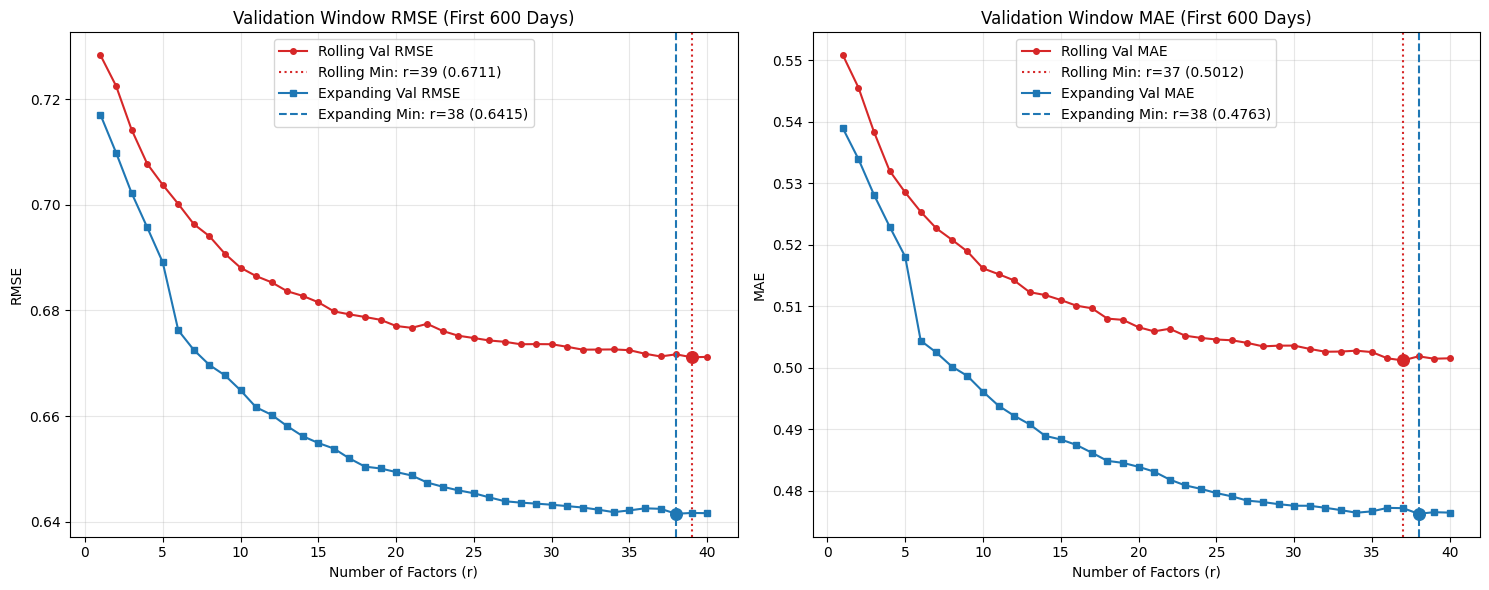

In [28]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Build a summary table using the validation phase metrics
summary = pd.DataFrame({
    'Method': ['Rolling (1000d)', 'Expanding'],
    'Best r (Val RMSE)': [
        roll_val_metrics['RMSE'].idxmin(),
        exp_val_metrics['RMSE'].idxmin(),
    ],
    'Min Val RMSE': [
        roll_val_metrics['RMSE'].min(),
        exp_val_metrics['RMSE'].min(),
    ],
    'Best r (Val MAE)': [
        roll_val_metrics['MAE'].idxmin(),
        exp_val_metrics['MAE'].idxmin(),
    ],
    'Min Val MAE': [
        roll_val_metrics['MAE'].min(),
        exp_val_metrics['MAE'].min(),
    ],
}).set_index('Method')

print('=== Validation Split Performance Comparison (First 600 Days) ===')
display(summary)

# 2. Side-by-side validation error curves (RMSE & MAE) to show how optimal r was selected
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True)

# --- Subplot 1: Validation RMSE ---
r_roll_rmse = roll_val_metrics['RMSE'].idxmin()
v_roll_rmse = roll_val_metrics.loc[r_roll_rmse, 'RMSE']
r_exp_rmse = exp_val_metrics['RMSE'].idxmin()
v_exp_rmse = exp_val_metrics.loc[r_exp_rmse, 'RMSE']

axes[0].plot(
    roll_val_metrics.index,
    roll_val_metrics['RMSE'],
    marker='o',
    markersize=4,
    color='tab:red',
    label='Rolling Val RMSE',
)
axes[0].axvline(
    r_roll_rmse,
    color='tab:red',
    linestyle=':',
    linewidth=1.5,
    label=f'Rolling Min: r={r_roll_rmse} ({v_roll_rmse:.4f})',
)
axes[0].scatter([r_roll_rmse], [v_roll_rmse], color='tab:red', s=70, zorder=5)

axes[0].plot(
    exp_val_metrics.index,
    exp_val_metrics['RMSE'],
    marker='s',
    markersize=4,
    color='tab:blue',
    label='Expanding Val RMSE',
)
axes[0].axvline(
    r_exp_rmse,
    color='tab:blue',
    linestyle='--',
    linewidth=1.5,
    label=f'Expanding Min: r={r_exp_rmse} ({v_exp_rmse:.4f})',
)
axes[0].scatter([r_exp_rmse], [v_exp_rmse], color='tab:blue', s=70, zorder=5)

axes[0].set_title('Validation Window RMSE (First 600 Days)')
axes[0].set_xlabel('Number of Factors (r)')
axes[0].set_ylabel('RMSE')
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# --- Subplot 2: Validation MAE ---
r_roll_mae = roll_val_metrics['MAE'].idxmin()
v_roll_mae = roll_val_metrics.loc[r_roll_mae, 'MAE']
r_exp_mae = exp_val_metrics['MAE'].idxmin()
v_exp_mae = exp_val_metrics.loc[r_exp_mae, 'MAE']

axes[1].plot(
    roll_val_metrics.index,
    roll_val_metrics['MAE'],
    marker='o',
    markersize=4,
    color='tab:red',
    label='Rolling Val MAE',
)
axes[1].axvline(
    r_roll_mae,
    color='tab:red',
    linestyle=':',
    linewidth=1.5,
    label=f'Rolling Min: r={r_roll_mae} ({v_roll_mae:.4f})',
)
axes[1].scatter([r_roll_mae], [v_roll_mae], color='tab:red', s=70, zorder=5)

axes[1].plot(
    exp_val_metrics.index,
    exp_val_metrics['MAE'],
    marker='s',
    markersize=4,
    color='tab:blue',
    label='Expanding Val MAE',
)
axes[1].axvline(
    r_exp_mae,
    color='tab:blue',
    linestyle='--',
    linewidth=1.5,
    label=f'Expanding Min: r={r_exp_mae} ({v_exp_mae:.4f})',
)
axes[1].scatter([r_exp_mae], [v_exp_mae], color='tab:blue', s=70, zorder=5)

axes[1].set_title('Validation Window MAE (First 600 Days)')
axes[1].set_xlabel('Number of Factors (r)')
axes[1].set_ylabel('MAE')
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

In [15]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

# 1. Setup Data and Configurations
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
log_df = np.log(df)
N_assets = df.shape[1]
T = len(log_df)
n_eval = evaluator.n_eval
start_idx = T - n_eval
eval_dates = df.index[-n_eval:]

# Convert to PyTorch tensor for accelerated calculations
X_raw = torch.tensor(log_df.values, dtype=torch.float32, device=device)

# 2. Run Out-Of-Sample Baseline OLS (AR(1) equivalent on each individual series)
ols_errors = []

for t in range(start_idx, T):
    # standardizing up to time t to prevent data leaks
    X_win = X_raw[:t]
    mean_t = X_win.mean(dim=0, keepdim=True)
    std_t = X_win.std(dim=0, keepdim=True)
    X_norm = (X_win - mean_t) / std_t
    x_actual_norm = (X_raw[t : t + 1] - mean_t) / std_t

    # Features: Lagged normalized series (time indices 0 to t-2)
    # Targets: Current normalized series (time indices 1 to t-1)
    Y_train = X_norm[1:, :]
    F_train = X_norm[:-1, :]
    f_latest = X_norm[-1:, :]

    # Individual OLS regression: Beta = (F_train^T @ F_train)^(-1) @ (F_train^T @ Y_train)
    num = (F_train * Y_train).sum(dim=0)
    den = (F_train ** 2).sum(dim=0)
    Beta_ols = num / den

    # Forecast next period
    x_pred = f_latest * Beta_ols
    err = (x_actual_norm - x_pred).cpu().numpy()[0]
    ols_errors.append(err)

# Convert error matrices to DataFrames
ols_errors_df = pd.DataFrame(ols_errors, index=eval_dates, columns=df.columns)

# 3. Calculate metrics for Baseline OLS on the test split (the last 200 days: start_idx=600, end_idx=800)
ols_test_err_vals = ols_errors_df.iloc[600:800].values
ols_rmse = np.sqrt(np.mean(ols_test_err_vals ** 2))
ols_mae = np.mean(np.abs(ols_test_err_vals))

# 4. Compare with optimal factor model test specifications
comparison_summary = pd.DataFrame({
    'Model Spec': [
        'Pure OLS Baseline (AR1)',
        f'Optimal Rolling Factor Model (r={best_roll_r})',
        f'Optimal Expanding Factor Model (r={best_exp_r})'
    ],
    'Out-of-Sample RMSE': [ols_rmse, test_rmse_roll, test_rmse_exp],
    'Out-of-Sample MAE': [ols_mae, test_mae_roll, test_mae_exp]
}).set_index('Model Spec')

print("=== Performance Comparison Table on Final 200-Day Test Window ===")
display(comparison_summary)


=== Performance Comparison Table on Final 200-Day Test Window ===


,Out-of-Sample RMSE,Out-of-Sample MAE
Model Spec,,
Pure OLS Baseline (AR1),0.647287,0.481818
Optimal Rolling Factor Model (r=38),0.653377,0.489417
Optimal Expanding Factor Model (r=38),0.625906,0.466287


Computing multivariate VAR(1) out-of-sample forecasts on: cpu...

=== Expanded Comparison Table on Final 200-Day Test Window ===


,Out-of-Sample RMSE,Out-of-Sample MAE
Model Spec,,
Multivariate VAR(1) Baseline,0.624356,0.465280
Optimal Expanding Factor Model (r=38),0.625906,0.466287
Pure OLS Baseline (AR1),0.647287,0.481818
Optimal Rolling Factor Model (r=38),0.653377,0.489417


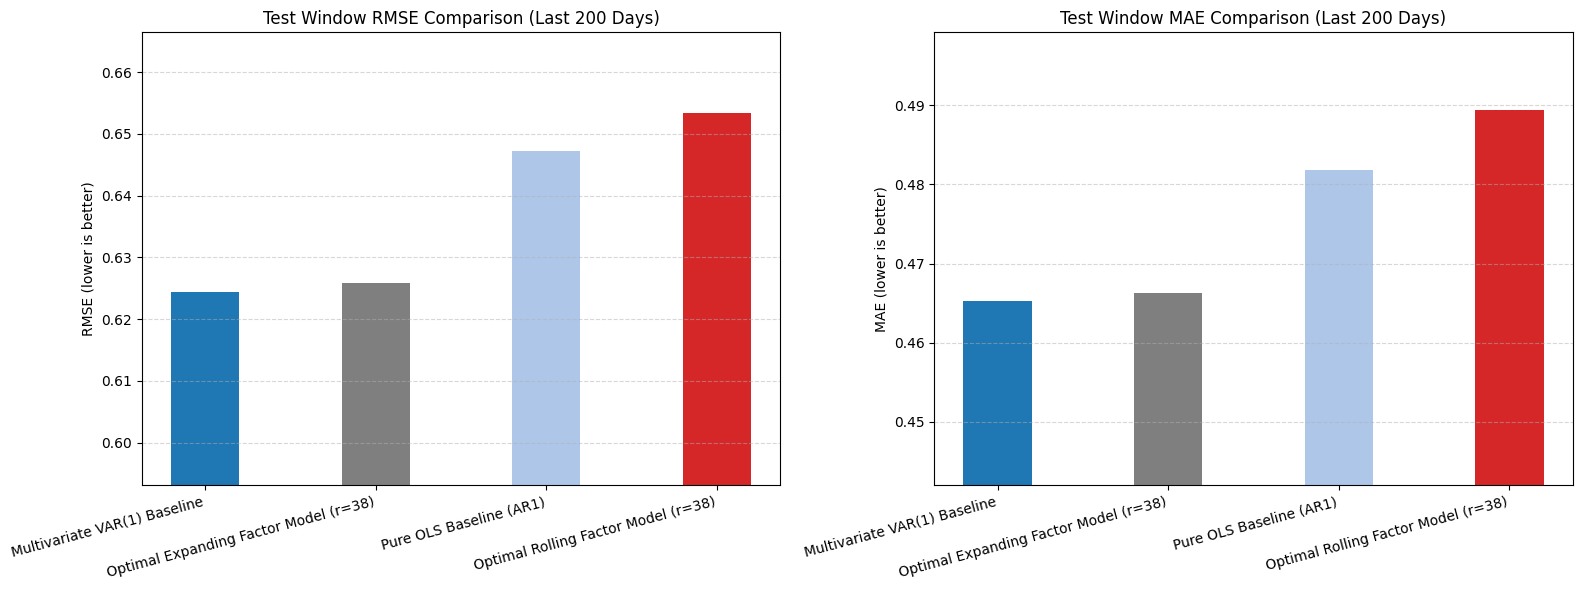

In [16]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

# 1. Setup Data and Configurations
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
log_df = np.log(df)
T, N = log_df.shape
n_eval = evaluator.n_eval
start_idx = T - n_eval
eval_dates = df.index[-n_eval:]

# Convert to PyTorch tensor for accelerated multivariate regression
X_raw = torch.tensor(log_df.values, dtype=torch.float32, device=device)

# 2. Run Out-Of-Sample VAR(1) Baseline
var_errors = []

print(f"Computing multivariate VAR(1) out-of-sample forecasts on: {device}...")
for t in range(start_idx, T):
    X_win = X_raw[:t]
    mean_t = X_win.mean(dim=0, keepdim=True)
    std_t = X_win.std(dim=0, keepdim=True)
    X_norm = (X_win - mean_t) / std_t
    x_actual_norm = (X_raw[t : t + 1] - mean_t) / std_t

    F_train = X_norm[:-1, :]
    Y_train = X_norm[1:, :]
    f_latest = X_norm[-1:, :]

    FtF = F_train.T @ F_train
    FtY = F_train.T @ Y_train
    Beta_VAR = torch.linalg.solve(FtF, FtY)

    x_pred = f_latest @ Beta_VAR
    err = (x_actual_norm - x_pred).cpu().numpy()[0]
    var_errors.append(err)

var_errors_df = pd.DataFrame(var_errors, index=eval_dates, columns=df.columns)

# 3. Calculate Performance Metrics on the test split (the last 200 days: start_idx=600, end_idx=800)
var_test_err_vals = var_errors_df.iloc[600:800].values
var_rmse = np.sqrt(np.mean(var_test_err_vals ** 2))
var_mae = np.mean(np.abs(var_test_err_vals))

# 4. Consolidate Comparison
comparison_summary['Out-of-Sample RMSE'] = comparison_summary['Out-of-Sample RMSE'].astype(float)
comparison_summary['Out-of-Sample MAE'] = comparison_summary['Out-of-Sample MAE'].astype(float)

comparison_summary.loc['Multivariate VAR(1) Baseline'] = [var_rmse, var_mae]
comparison_summary = comparison_summary.sort_values('Out-of-Sample RMSE')

print("\n=== Expanded Comparison Table on Final 200-Day Test Window ===")
display(comparison_summary)

# 5. Visualize Performance without Warnings
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
colors = ['#1f77b4', '#7f7f7f', '#aec7e8', '#d62728']

# RMSE Bar Chart
ax1.bar(comparison_summary.index, comparison_summary['Out-of-Sample RMSE'], color=colors[:len(comparison_summary)], width=0.4)
ax1.set_title('Test Window RMSE Comparison (Last 200 Days)')
ax1.set_ylabel('RMSE (lower is better)')
ax1.set_ylim(comparison_summary['Out-of-Sample RMSE'].min() * 0.95, comparison_summary['Out-of-Sample RMSE'].max() * 1.02)
ax1.grid(True, linestyle='--', alpha=0.5, axis='y')
ax1.set_xticks(range(len(comparison_summary)))
ax1.set_xticklabels(comparison_summary.index, rotation=15, ha='right')

# MAE Bar Chart
ax2.bar(comparison_summary.index, comparison_summary['Out-of-Sample MAE'], color=colors[:len(comparison_summary)], width=0.4)
ax2.set_title('Test Window MAE Comparison (Last 200 Days)')
ax2.set_ylabel('MAE (lower is better)')
ax2.set_ylim(comparison_summary['Out-of-Sample MAE'].min() * 0.95, comparison_summary['Out-of-Sample MAE'].max() * 1.02)
ax2.grid(True, linestyle='--', alpha=0.5, axis='y')
ax2.set_xticks(range(len(comparison_summary)))
ax2.set_xticklabels(comparison_summary.index, rotation=15, ha='right')

plt.tight_layout()
plt.show()

In [1]:
import numpy as np
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler

def run_simple_var1_lasso_fast(rv5_panel, t_start=1375, val_len=600, n_alphas=25):
    # 1. Causal VAR(1) alignment: yesterday's rv5 -> today's rv5
    X = rv5_panel[:-1]  # (T_total, 40)
    Y = rv5_panel[1:]   # (T_total, 40)
    T_total, N = X.shape
    n_oos = T_total - t_start

    # Ordered largest -> smallest so warm_start reuses solutions smoothly
    alphas = np.geomspace(0.5, 1e-5, n_alphas)
    preds_all = np.zeros((n_oos, n_alphas, N))

    # SPEEDUP 1: Create the model ONCE outside the loops with warm_start=True
    # and precompute=True (uses fast 40x40 Gram matrix since n_samples >> 40)
    model = Lasso(
        fit_intercept=True,
        warm_start=True,
        precompute=True,
        max_iter=2000,
        tol=1e-5,
    )

    # 2. Walk-forward expanding window
    for step in range(n_oos):
        t = t_start + step

        # Leak-free standardization strictly on [0 : t-1]
        scaler = StandardScaler()
        X_train = scaler.fit_transform(X[:t])
        X_today = scaler.transform(X[t : t + 1])  # (1, 40)
        Y_train = Y[:t]

        # SPEEDUP 2: Precompute the 40x40 Gram matrix once per day
        # instead of recomputing it 25 times inside the alpha loop
        gram = X_train.T @ X_train
        model.precompute = gram

        # Fit LASSO for each penalty level
        for m, alpha in enumerate(alphas):
            model.alpha = alpha
            model.fit(X_train, Y_train)
            preds_all[step, m] = model.predict(X_today)[0]

    # 3. 600-day validation -> 200-day untouched final test
    Y_oos = Y[t_start:]
    val_rmse = np.sqrt(np.mean((preds_all[:val_len] - Y_oos[:val_len, None, :]) ** 2, axis=(0, 2)))

    best_idx = int(np.argmin(val_rmse))
    test_preds = preds_all[val_len:, best_idx, :]
    test_rmse = np.sqrt(np.mean((test_preds - Y_oos[val_len:]) ** 2))

    return alphas, val_rmse, alphas[best_idx], test_preds, test_rmse

In [2]:
import numpy as np
from sklearn.linear_model import lasso_path
from sklearn.preprocessing import StandardScaler

def run_simple_var1_lasso_rolling_fast(rv5_panel, window_len=1375, t_start=1375, val_len=600, n_alphas=25):
    if t_start < window_len:
        raise ValueError(f"t_start ({t_start}) must be at least window_len ({window_len}).")

    # 1. Causal VAR(1) alignment
    X = rv5_panel[:-1]  # (T_total, 40)
    Y = rv5_panel[1:]   # (T_total, 40)
    T_total, N = X.shape
    n_oos = T_total - t_start

    # Must be ordered descending (largest penalty -> smallest penalty) for warm starts
    alphas = np.geomspace(0.5, 1e-5, n_alphas)
    preds_all = np.zeros((n_oos, n_alphas, N))

    # 2. Walk-forward fixed rolling window
    for step in range(n_oos):
        t = t_start + step
        train_start = t - window_len

        # Standardize X strictly on the rolling window (gives X_train mean = 0, std = 1)
        scaler = StandardScaler()
        X_train = scaler.fit_transform(X[train_start:t])      # (window_len, 40)
        X_today = scaler.transform(X[t : t + 1])              # (1, 40)

        # Center Y manually to replicate fit_intercept=True
        Y_train = Y[train_start:t]                            # (window_len, 40)
        Y_mean = Y_train.mean(axis=0, keepdims=True)          # (1, 40)
        Y_train_centered = Y_train - Y_mean

        # Compute all 25 alphas in one compiled Cython pass
        # Returns coefs with shape: (n_targets=40, n_features=40, n_alphas=25)
        _, coefs, _ = lasso_path(
            X_train,
            Y_train_centered,
            alphas=alphas,
            max_iter=2000,
            tol=1e-5
        )

        # Vectorized prediction across all 25 alphas at once:
        # X_today (1, 40) @ coefs -> (40 targets, 1, 25 alphas) -> transpose to (25, 40)
        preds_step = np.einsum("ij,kjm->mk", X_today, coefs) + Y_mean
        preds_all[step] = preds_step

    # 3. Validation & Out-of-Sample Test Evaluation
    Y_oos = Y[t_start:]
    val_rmse = np.sqrt(np.mean((preds_all[:val_len] - Y_oos[:val_len, None, :]) ** 2, axis=(0, 2)))

    best_idx = int(np.argmin(val_rmse))
    test_preds = preds_all[val_len:, best_idx, :]
    test_rmse = np.sqrt(np.mean((test_preds - Y_oos[val_len:]) ** 2))

    return alphas, val_rmse, alphas[best_idx], test_preds, test_rmse

In [ ]:
import time
import numpy as np

# 1. Convert DataFrame -> contiguous float64 NumPy array
rv5_arr = np.ascontiguousarray(df.to_numpy(dtype=np.float64))

# 2A. Full expanding-window run (default parameters: t_start=1375, val_len=600, n_alphas=25)
t0 = time.perf_counter()
alphas, val_rmse, best_alpha, test_preds, test_rmse = run_simple_var1_lasso_fast(
    rv5_arr
)

# 2B. Optional: ~1-second smoke test on the last 100 days with 6 alphas
# t0 = time.perf_counter()
# alphas, val_rmse, best_alpha, test_preds, test_rmse = run_simple_var1_lasso_fast(
#     rv5_arr,
#     t_start=len(rv5_arr) - 101,  # -101 because X, Y drop 1 row during VAR(1) alignment
#     val_len=75,
#     n_alphas=6,
# )

print(f"Elapsed: {time.perf_counter() - t0:.2f}s")
for a, r in zip(alphas, val_rmse):
    print(f"alpha={a:.5f} -> val_rmse={r:.6f}")

print(f"\nBest alpha: {best_alpha:.5f} | Test RMSE: {test_rmse:.6f}")

In [ ]:
# --- Run Expanding-Window VAR(1) LASSO ---
rv5_arr = np.ascontiguousarray(df.to_numpy(dtype=np.float64))

t0 = time.perf_counter()
alphas_rolling, val_rmse_rolling, best_alpha_rolling, test_preds_rolling, test_rmse_rolling = run_simple_var1_lasso_rolling_fast(
    rv5_arr,
    t_start=1375,
    val_len=600,
    n_alphas=25,
)

print(f"Elapsed: {time.perf_counter() - t0:.2f}s")
for a, r in zip(alphas_rolling, val_rmse_rolling):
    print(f"alpha={a:.5f} -> val_rmse={r:.6f}")

print(f"\nBest alpha: {best_alpha_rolling:.5f} | Test RMSE: {test_rmse_rolling:.6f}")